# LUMA - Lokalny Urok Mistrzostwa Artystycznego

LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień, coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalnie promocje i sezonowość

## Import bibliotek

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [20]:
RNG_SEED = 20261020
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261020


### Zdefiniowanie stałych

In [21]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["CERAMIKA", "TEKSTYLIA", "BIŻUTERIA", "RĘKODZIEŁO", "PRZETWORY", "DEKORACJE", "STOLARKA", "MASARSTWO", "ALKOHOLE"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne(syntetyczne)

In [22]:
catalog = pd.DataFrame(
    {
        "category" : CATEGORIES,
        "demand_loc_base" : [120, 180, 130, 80, 160, 150, 70, 90, 110], #sredni lokalny popyt (szt./tydz)
        "demand_tur_base" : [60, 40, 80, 30, 90, 30, 50, 40, 80], # sredni popyt turystyczny (szt./tydz.)
        "price_pln_base" : [8, 120, 150, 230, 40, 35, 250, 215, 135], #srednia cena jednostkowa
    }
)

Wyliczony "typowy" średni przychód tygodniowy: (lokalni + turyści) * cena

In [23]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"])*catalog["price_pln_base"]

In [24]:
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,CERAMIKA,120,60,8,1440
1,TEKSTYLIA,180,40,120,26400
2,BIŻUTERIA,130,80,150,31500
3,RĘKODZIEŁO,80,30,230,25300
4,PRZETWORY,160,90,40,10000
5,DEKORACJE,150,30,35,6300
6,STOLARKA,70,50,250,30000
7,MASARSTWO,90,40,215,27950
8,ALKOHOLE,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

#### Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [25]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur 
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]

### Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [26]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

### Generowanie danych tygodniowych

In [27]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

## Wygenerowanie danych tygodniowych

In [28]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,CERAMIKA,688,392,1080,8
1,TEKSTYLIA,21240,3360,24600,120
2,BIŻUTERIA,13350,11700,25050,150
3,RĘKODZIEŁO,22540,6440,28980,230
4,PRZETWORY,7720,3680,11400,40
5,DEKORACJE,4900,1120,6020,35
6,STOLARKA,19000,14250,33250,250
7,MASARSTWO,18275,8815,27090,215
8,ALKOHOLE,18630,10260,28890,135


Łączny przychód w tygodniu 1 (PLN):  186360


### Analiza i wizualizacja danych

##### Podstawowe wykresy

<Axes: >

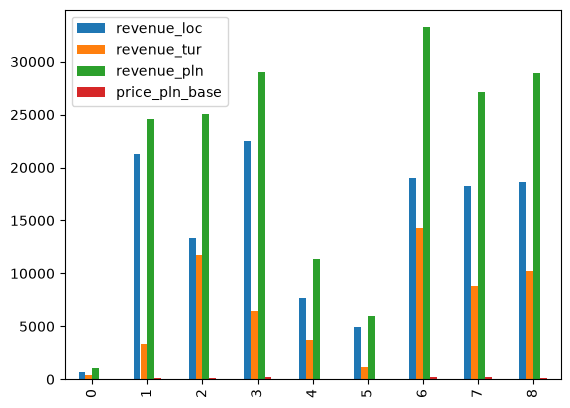

In [29]:
t1.plot.bar()

<Axes: >

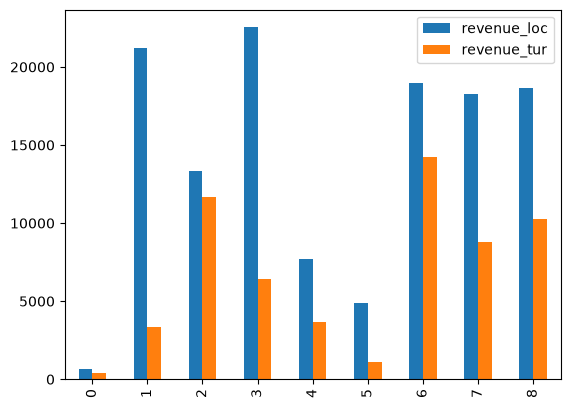

In [30]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

##### Minimalny wykres

<Axes: >

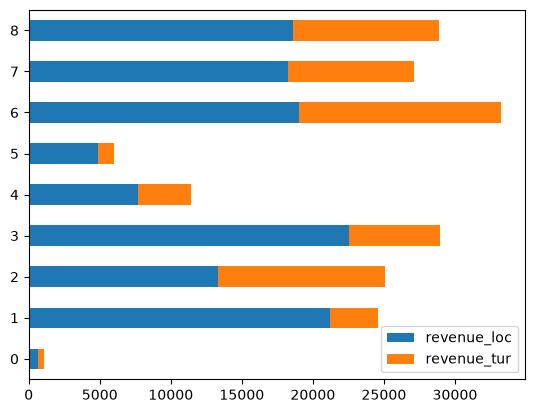

In [31]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

#### Jawne tworzenie i wyświetlanie wykresu

<BarContainer object of 9 artists>

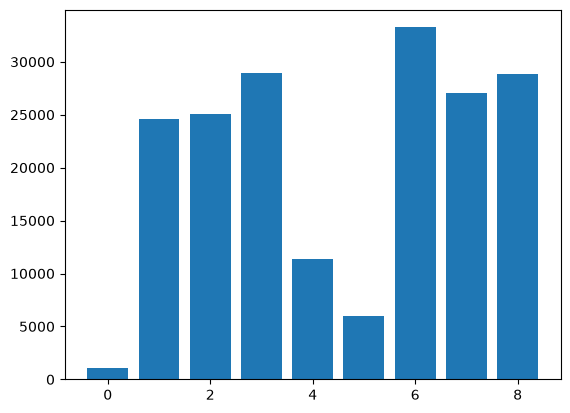

In [32]:
hoights = t1["revenue_pln"]
plt.bar(range(len(hoights)), hoights)

In [33]:
hoights = t1["revenue_pln"]
categories = t1["category"]

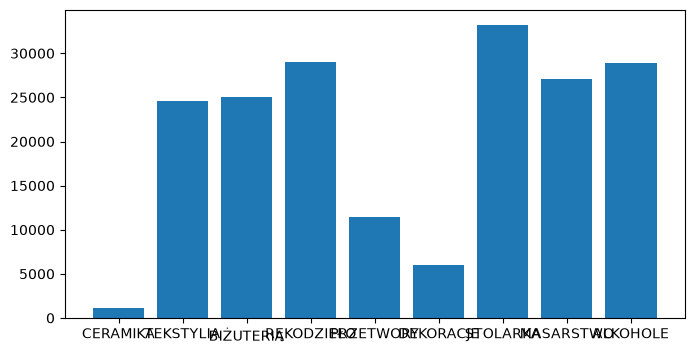

In [34]:
plt.figure(figsize=(8, 4))
plt.bar(categories, hoights)
plt.show()

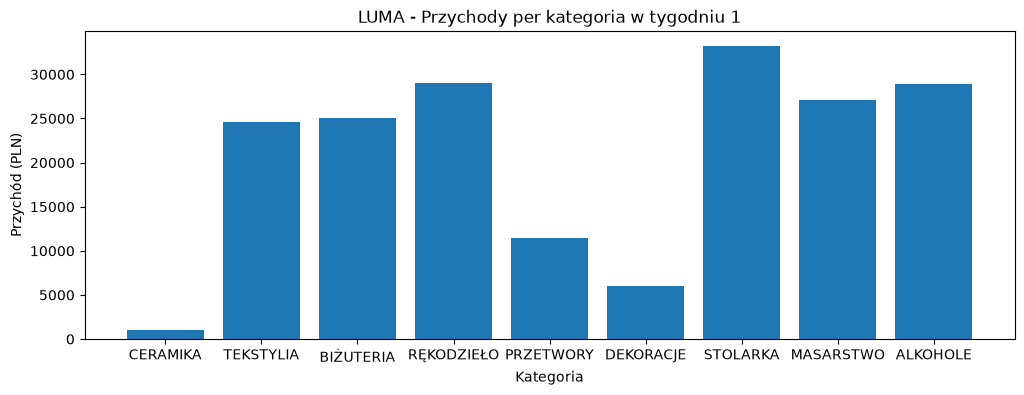

In [35]:
plt.figure(figsize=(12, 4))
plt.bar(categories, hoights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()